<a href="https://colab.research.google.com/github/Lekhana-Y/ML/blob/main/lda_ml_l7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload and extract dataset

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

print(df.head())

Saving time_series_data_human_activities.csv to time_series_data_human_activities (1).csv
   user activity      timestamp  x-axis  y-axis  z-axis
0     1  Walking  4991922345000    0.69   10.80   -2.03
1     1  Walking  4991972333000    6.85    7.44   -0.50
2     1  Walking  4992022351000    0.93    5.63   -0.50
3     1  Walking  4992072339000   -2.11    5.01   -0.69
4     1  Walking  4992122358000   -4.59    4.29   -1.95


Load the CSV

In [ ]:
X = df[['x-axis', 'y-axis', 'z-axis']]
y = df['activity']

print("Features:", X.shape)
print("Classes:", y.unique())

Features: (1073623, 3)
Classes: ['Walking' 'Jogging' 'Upstairs' 'Downstairs' 'Sitting' 'Standing']


In [ ]:
print("Columns:")
print(df.columns)

print("\nActivity counts:")
print(df['activity'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Columns:
Index(['user', 'activity', 'timestamp', 'x-axis', 'y-axis', 'z-axis'], dtype='object')

Activity counts:
activity
Walking       417901
Jogging       324600
Upstairs      122598
Downstairs    100192
Sitting        59939
Standing       48393
Name: count, dtype: int64

Missing values:
user         0
activity     0
timestamp    0
x-axis       0
y-axis       0
z-axis       0
dtype: int64


Train-test split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (805217, 3)
Testing data: (268406, 3)


Apply LDA

In [ ]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)

y_pred = lda.predict(X_test)

print("Prediction completed.")

Prediction completed.


Check accuracy

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.4788454803543885

Classification Report:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

  Downstairs       0.00      0.00      0.00     25048
     Jogging       0.53      0.40      0.46     81150
     Sitting       0.50      0.54      0.52     14985
    Standing       0.00      0.00      0.00     12098
    Upstairs       0.00      0.00      0.00     30650
     Walking       0.46      0.84      0.59    104475

    accuracy                           0.48    268406
   macro avg       0.25      0.30      0.26    268406
weighted avg       0.37      0.48      0.40    268406



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


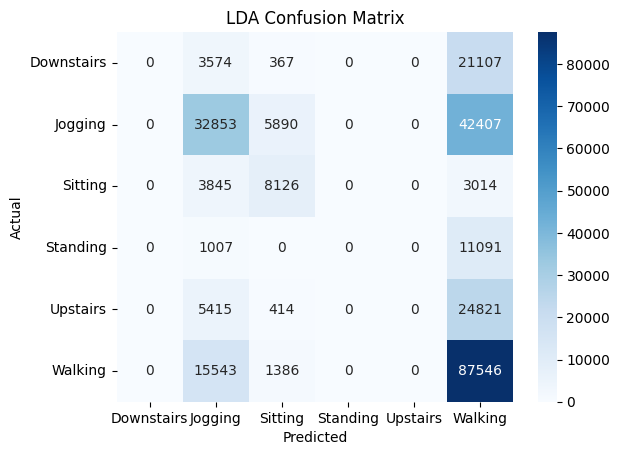

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=lda.classes_,
    yticklabels=lda.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LDA Confusion Matrix")
plt.show()

LDA dimensionality reduction

In [ ]:
lda_2d = LinearDiscriminantAnalysis(n_components=1)

X_lda = lda_2d.fit_transform(X, y)

print("Original shape:", X.shape)
print("LDA shape:", X_lda.shape)

Original shape: (1073623, 3)
LDA shape: (1073623, 1)


In [ ]:
print(df.shape)
print(df['activity'].value_counts())
print(df['activity'].unique())

(1073623, 6)
activity
Walking       417901
Jogging       324600
Upstairs      122598
Downstairs    100192
Sitting        59939
Standing       48393
Name: count, dtype: int64
['Walking' 'Jogging' 'Upstairs' 'Downstairs' 'Sitting' 'Standing']


In [ ]:
X = df[['x-axis', 'y-axis', 'z-axis']]
y = df['activity']

print("Features shape:", X.shape)
print("Number of classes:", y.nunique())
print("Classes:", y.unique())

Features shape: (1073623, 3)
Number of classes: 6
Classes: ['Walking' 'Jogging' 'Upstairs' 'Downstairs' 'Sitting' 'Standing']


In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_2d = LinearDiscriminantAnalysis(n_components=2)

X_lda = lda_2d.fit_transform(X, y)

print("Original shape:", X.shape)
print("LDA shape:", X_lda.shape)

Original shape: (1073623, 3)
LDA shape: (1073623, 2)


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


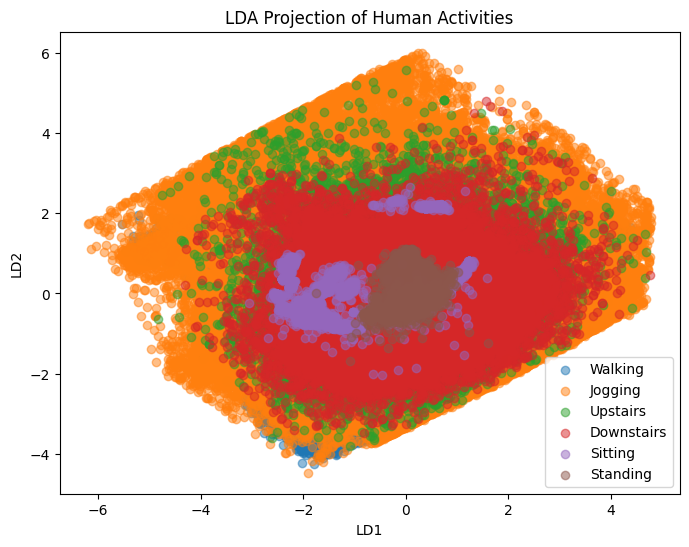

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for activity in y.unique():

    mask = y == activity

    plt.scatter(
        X_lda[mask, 0],
        X_lda[mask, 1],
        label=activity,
        alpha=0.5
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA Projection of Human Activities")
plt.legend()
plt.show()

In [ ]:
lda_2d = LinearDiscriminantAnalysis(n_components=2)

X_lda = lda_2d.fit_transform(X, y)

print(X_lda.shape)
print(lda_2d.explained_variance_ratio_)

(1073623, 2)
[0.78252601 0.17499393]


with diff libraries

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)



Saving time_series_data_human_activities.csv to time_series_data_human_activities (2).csv


In [ ]:
X = df[["x-axis", "y-axis", "z-axis"]].values
y = df["activity"].values

print("Features:", X.shape)
print("Classes:", np.unique(y))

Features: (1073623, 3)
Classes: ['Downstairs' 'Jogging' 'Sitting' 'Standing' 'Upstairs' 'Walking']


In [ ]:
X_torch = torch.tensor(X, dtype=torch.float32)

print("PyTorch tensor shape:", X_torch.shape)

PyTorch tensor shape: torch.Size([1073623, 3])


In [ ]:
classes = np.unique(y)

overall_mean = X_torch.mean(dim=0)

class_means = {}

for c in classes:
    class_data = X_torch[y == c]
    class_means[c] = class_data.mean(dim=0)

print("Overall mean:")
print(overall_mean)

print("\nClass means:")
for c in classes:
    print(c, class_means[c])

Overall mean:
tensor([0.6721, 7.3327, 0.4025])

Class means:
Downstairs tensor([0.4727, 8.6202, 0.6857])
Jogging tensor([-0.2271,  5.6324, -0.1558])
Sitting tensor([1.8563, 1.8534, 6.5597])
Standing tensor([-1.1783,  8.9874,  0.5801])
Upstairs tensor([0.3822, 8.1295, 0.3243])
Walking tensor([ 1.5477,  8.7052, -0.1126])


In [ ]:
S_W = torch.zeros((X_torch.shape[1], X_torch.shape[1]))

for c in classes:

    class_data = X_torch[y == c]
    mean = class_means[c]

    centered = class_data - mean

    S_W += centered.T @ centered

print("Within-class scatter matrix:")
print(S_W)

Within-class scatter matrix:
tensor([[50518852.0000,   968180.3750,  2011705.5000],
        [  968180.3750, 44768432.0000,  2356999.7500],
        [ 2011705.5000,  2356999.7500, 22131358.0000]])


In [ ]:
S_B = torch.zeros((X_torch.shape[1], X_torch.shape[1]))

for c in classes:

    class_data = X_torch[y == c]
    n = class_data.shape[0]

    mean_diff = (class_means[c] - overall_mean).reshape(-1, 1)

    S_B += n * (mean_diff @ mean_diff.T)

print("Between-class scatter matrix:")
print(S_B)

Between-class scatter matrix:
tensor([[  846898.0000,   407402.1250,   392702.5625],
        [  407402.1250,  3901656.0000, -1966414.2500],
        [  392702.5625, -1966414.2500,  2494730.5000]])


In [ ]:
S_W_inv = torch.linalg.pinv(S_W)

matrix = S_W_inv @ S_B

eigenvalues, eigenvectors = torch.linalg.eig(matrix)

eigenvalues = eigenvalues.real
eigenvectors = eigenvectors.real

# Sort eigenvectors by largest eigenvalue
indices = torch.argsort(eigenvalues, descending=True)

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("Eigenvalues:")
print(eigenvalues)

print("\nDiscriminant directions:")
print(eigenvectors)

Eigenvalues:
tensor([0.1768, 0.0395, 0.0096])

Discriminant directions:
tensor([[-0.0110, -0.3842,  0.8304],
        [-0.5112, -0.6062, -0.3456],
        [ 0.8594, -0.6964, -0.4370]])


In [ ]:
W = eigenvectors[:, :2]

print("Selected LDA directions:")
print(W)

Selected LDA directions:
tensor([[-0.0110, -0.3842],
        [-0.5112, -0.6062],
        [ 0.8594, -0.6964]])


In [ ]:
X_lda_torch = X_torch @ W

print("Original shape:", X_torch.shape)
print("LDA shape:", X_lda_torch.shape)

Original shape: torch.Size([1073623, 3])
LDA shape: torch.Size([1073623, 2])


In [ ]:
sample_size = 10000

indices = torch.randperm(len(X_lda_torch))[:sample_size]

X_plot = X_lda_torch[indices].numpy()
y_plot = y[indices.numpy()]

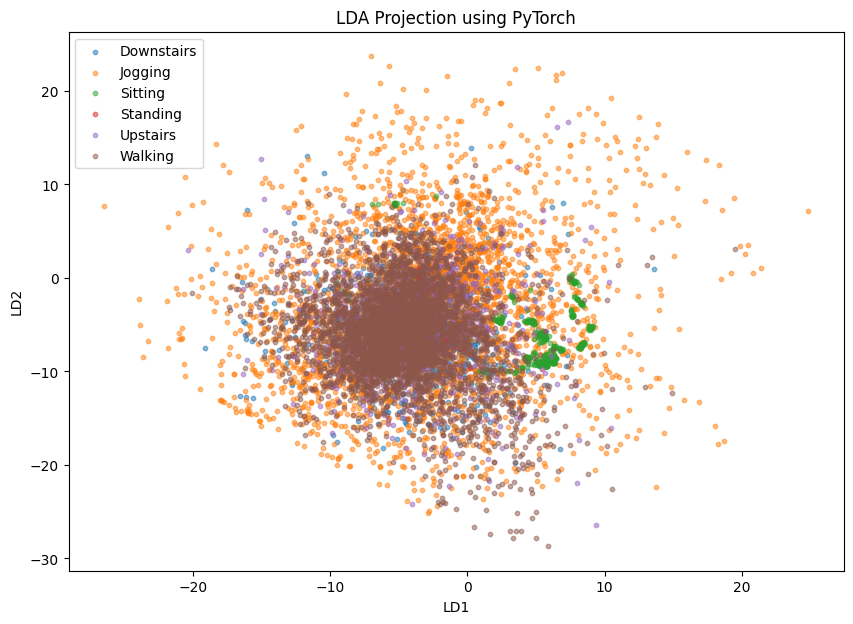

In [ ]:
plt.figure(figsize=(10, 7))

for c in classes:

    mask = y_plot == c

    plt.scatter(
        X_plot[mask, 0],
        X_plot[mask, 1],
        label=c,
        alpha=0.5,
        s=10
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA Projection using PyTorch")
plt.legend()
plt.show()

In [ ]:
selected_values = eigenvalues[:2]

ratio = selected_values / eigenvalues[eigenvalues > 0].sum()

print("LD1:", ratio[0].item() * 100, "%")
print("LD2:", ratio[1].item() * 100, "%")
print("Total:", ratio.sum().item() * 100, "%")

LD1: 78.25260758399963 %
LD2: 17.499393224716187 %
Total: 95.75200080871582 %
